# EDA: V1 responses to oriented gratings

Look at the data before choosing a model: audit the files, view the spikes of a whole session and of one neuron,
check how to count spikes and whether the counts are stable, then choose the neurons for the homework.
This notebook only describes the data; the models are in `models.py`, the fits in `fit.py` and `generalize.py`.
Run `make_all.py` first: the notebook reads `out/tuning.csv` and `out/neurons.csv`.

In [1]:
import glob
import os

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from common import DATA, NEURON, NOISY, OUT, SESSION
from counts import load_session

%matplotlib inline

## 1. Audit the files

Each session holds `spikes` (a V1 and a V2 array, stored as trials x ms x neurons) and `stim` (a code 1-8 per trial).

In [2]:
for path in sorted(glob.glob(f'{DATA}/*.mat')):
    with h5py.File(path, 'r') as f:
        v1, v2 = f[f['spikes'][0, 0]], f[f['spikes'][1, 0]]
        codes, n = np.unique(f['stim'][0], return_counts=True)
        print(os.path.basename(path), '| V1', v1.shape, '| V2', v2.shape, '|', v1.dtype,
              '| trials per code', dict(zip(codes.astype(int), n)))

105l001p16_spikes.mat | V1 (3200, 1280, 159) | V2 (3200, 1280, 25) | float64 | trials per code {1: 400, 2: 400, 3: 400, 4: 400, 5: 400, 6: 400, 7: 400, 8: 400}
106r001p26_spikes.mat | V1 (3200, 1280, 109) | V2 (3200, 1280, 30) | float64 | trials per code {1: 400, 2: 400, 3: 400, 4: 400, 5: 400, 6: 400, 7: 400, 8: 400}
106r002p70_spikes.mat | V1 (3200, 1280, 88) | V2 (3200, 1280, 24) | float64 | trials per code {1: 400, 2: 400, 3: 400, 4: 400, 5: 400, 6: 400, 7: 400, 8: 400}
107l002p67_spikes.mat | V1 (3200, 1280, 97) | V2 (3200, 1280, 31) | float64 | trials per code {1: 400, 2: 400, 3: 400, 4: 400, 5: 400, 6: 400, 7: 400, 8: 400}
107l003p143_spikes.mat | V1 (3200, 1280, 111) | V2 (3200, 1280, 37) | float64 | trials per code {1: 400, 2: 400, 3: 400, 4: 400, 5: 400, 6: 400, 7: 400, 8: 400}


In [3]:
spikes, stim = load_session(SESSION)  # trials x ms x V1 neurons
theta = (stim - 1) * 22.5             # 8 orientations in 22.5 deg steps (Xia et al. 2024)
print('shape', spikes.shape, '| values', spikes.min(), 'to', spikes.max(), '| total spikes', spikes.sum())
print('orientations', np.unique(theta))
print('codes of the first 16 trials', stim[:16])
print('every block of 8 consecutive trials shows each code once:',
      all(sorted(block) == list(range(1, 9)) for block in stim.reshape(-1, 8)))

shape (3200, 1280, 111) | values 0 to 1 | total spikes 15885866
orientations [  0.   22.5  45.   67.5  90.  112.5 135.  157.5]
codes of the first 16 trials [3 7 5 4 1 6 8 2 7 6 5 8 1 4 3 2]
every block of 8 consecutive trials shows each code once: True


Five sessions, 3200 trials each (400 per code), 1280 bins of 1 ms. Every bin holds 0 or 1 spike, so the response
of a trial is simply the sum of its 1280 bins. The trials come in 400 blocks of 8 that show every orientation once,
in random order. We analyse V1 only.

## 2. The whole session

Spike count of every neuron on every trial (divided by the neuron's mean), and the population rate across the session.

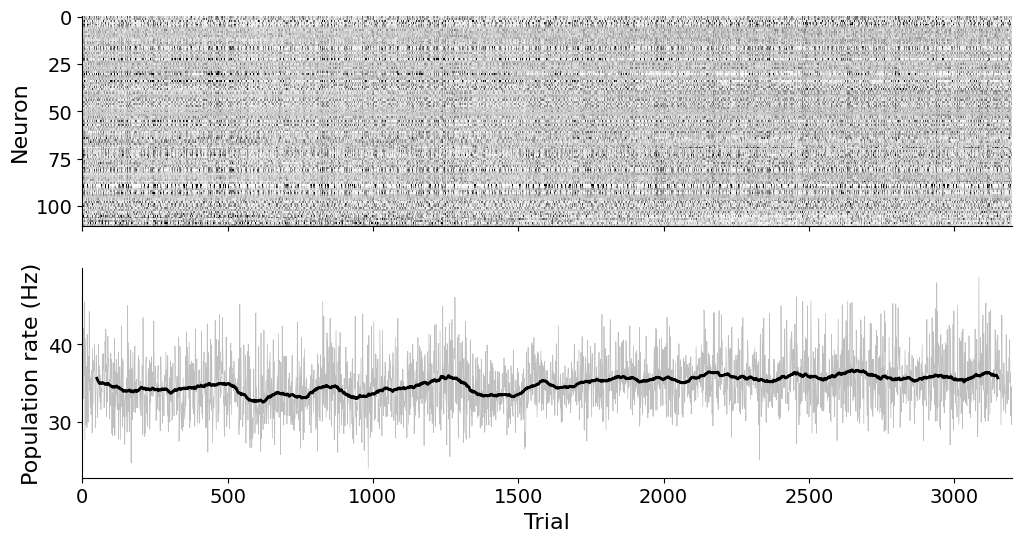

population rate, first vs last 500 trials (Hz): 34.6 35.7
drift (corr. of count residual with trial index): median 0.093 | |r| > 0.3 in 22 of 111 neurons


In [4]:
counts = spikes.sum(axis=1)  # trials x neurons
rate = pd.Series(counts.mean(axis=1) / 1.28)
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axs[0].imshow((counts / counts.mean(axis=0)).T, aspect='auto', cmap='Greys', vmax=3, interpolation='none')
axs[0].set_ylabel('Neuron')
axs[1].plot(rate, color='0.75', lw=0.5)
axs[1].plot(rate.rolling(100, center=True).mean(), color='k')
axs[1].set(xlabel='Trial', ylabel='Population rate (Hz)')
plt.show()
neurons = pd.read_csv(f'{OUT}/neurons.csv')
nrn = neurons[neurons.session == SESSION].set_index('neuron')
print('population rate, first vs last 500 trials (Hz):', rate[:500].mean().round(1), rate[-500:].mean().round(1))
print('drift (corr. of count residual with trial index): median', nrn.drift.median().round(3),
      '| |r| > 0.3 in', (nrn.drift.abs() > 0.3).sum(), 'of', len(nrn), 'neurons')

The population rate is stable over the session, but about a fifth of the neurons drift (their count at a fixed
orientation changes with time). The neurons chosen below drift little, and the train/validation/test split draws
trials at random from the whole session, so a slow drift affects all splits alike.

## 3. One neuron, zoomed in

All 3200 trials of the selected neuron sorted by orientation, a close-up of single trials, and the PSTH of each orientation.

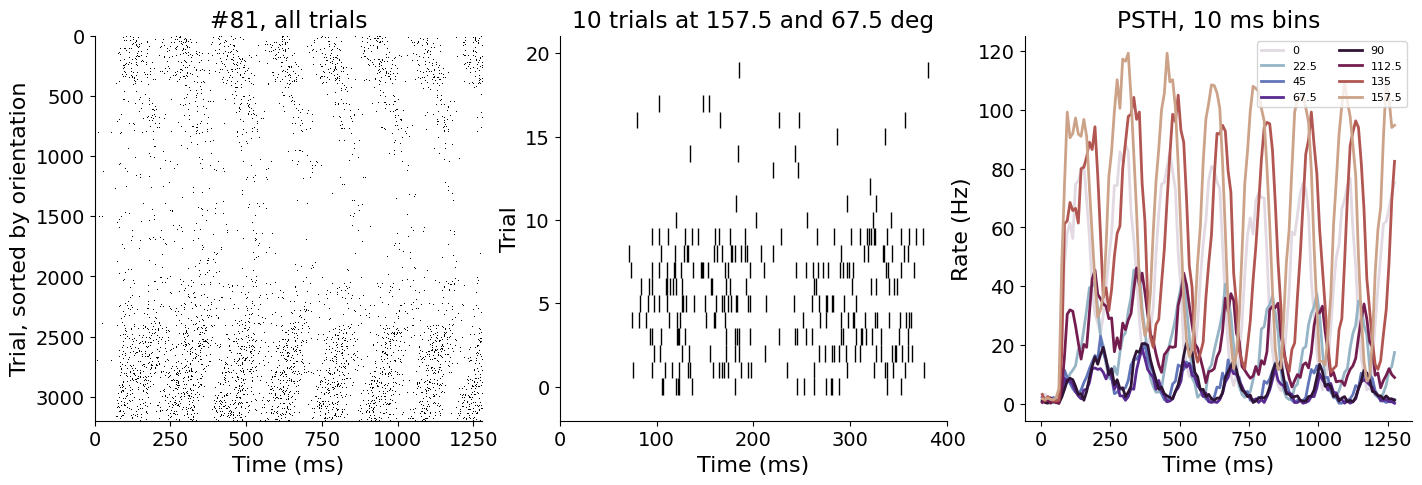

preferred orientation 157.5 | rate in the first 50 ms vs 50-1280 ms (Hz): 1.6 68.1
response onset (first 5 ms bin above 3x the 0-50 ms rate): 65 ms
main modulation frequency of the PSTH: 6.25 Hz


In [5]:
s = spikes[:, :, NEURON]
ori = np.unique(theta)
pref = ori[np.argmax([s[theta == t].sum() for t in ori])]
fig, axs = plt.subplots(1, 3, figsize=(17, 5))
axs[0].imshow(s[np.argsort(theta, kind='stable')], aspect='auto', cmap='Greys', interpolation='none')
axs[0].set(xlabel='Time (ms)', ylabel='Trial, sorted by orientation', title=f'#{NEURON}, all trials')
trials = np.r_[np.flatnonzero(theta == pref)[:10], np.flatnonzero(theta == (pref + 90) % 180)[:10]]
axs[1].eventplot([np.flatnonzero(s[i]) for i in trials], color='k', linewidths=1)
axs[1].set(xlim=(0, 400), xlabel='Time (ms)', ylabel='Trial', title=f'10 trials at {pref:g} and {(pref + 90) % 180:g} deg')
colors = plt.cm.twilight(np.linspace(0, 1, 9))
for t, c in zip(ori, colors):
    axs[2].plot(np.arange(5, 1280, 10), s[theta == t].reshape(-1, 128, 10).mean(axis=(0, 2)) * 1000, color=c, label=f'{t:g}')
axs[2].set(xlabel='Time (ms)', ylabel='Rate (Hz)', title='PSTH, 10 ms bins')
axs[2].legend(fontsize=8, ncol=2)
plt.show()
psth = s[theta == pref].mean(axis=0)
rate5 = psth.reshape(-1, 5).mean(axis=1) * 1000  # Hz in 5 ms bins
freq = np.fft.rfftfreq(1280, 1e-3)
print('preferred orientation', pref, '| rate in the first 50 ms vs 50-1280 ms (Hz):',
      (psth[:50].mean() * 1000).round(1), (psth[50:].mean() * 1000).round(1))
print('response onset (first 5 ms bin above 3x the 0-50 ms rate):', 5 * np.argmax(rate5 > 3 * rate5[:10].mean()), 'ms')
print('main modulation frequency of the PSTH:', freq[1:][np.argmax(np.abs(np.fft.rfft(psth - psth.mean()))[1:])], 'Hz')

The neuron is almost silent for the first ~65 ms (response latency), then fires in bursts locked to the drift
cycle of the grating (6.25 Hz). The 1280 ms count spans 8 full cycles, so it does not depend on the grating phase.
Xia et al. (2024) drop the first 100 ms (latency); this barely changes the tuning:

In [6]:
late = spikes[:, 100:, :].sum(axis=1)
tc_full = np.array([counts[theta == t].mean(axis=0) for t in ori])
tc_late = np.array([late[theta == t].mean(axis=0) for t in ori])
r = [np.corrcoef(tc_full[:, i], tc_late[:, i])[0, 1] for i in range(counts.shape[1])]
print('share of spikes in the first 100 ms:', (1 - late.sum() / counts.sum()).round(3))
print('correlation between tuning curves from 0-1280 and 100-1280 ms: median', np.round(np.median(r), 4), '| min', np.round(np.min(r), 3))

share of spikes in the first 100 ms: 0.041
correlation between tuning curves from 0-1280 and 100-1280 ms: median 0.9996 | min 0.966


## 4. Spike counts: noise and drift

Least squares treats every point alike, so check what the noise around each mean looks like.

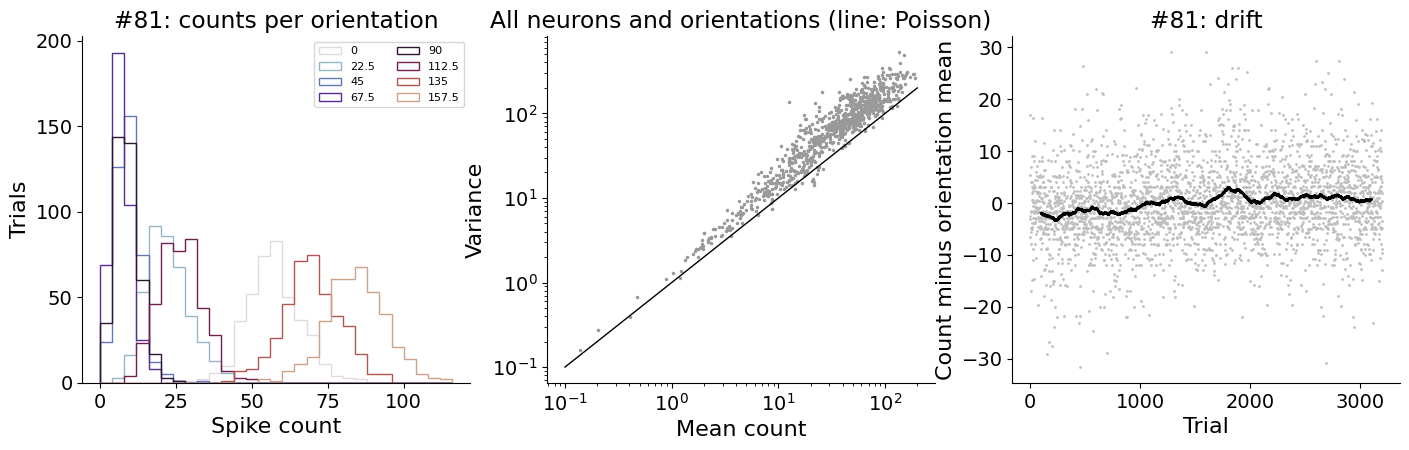

#81: SD per orientation [8.9, 7.1, 4.1, 3.5, 4.0, 7.0, 9.5, 9.9]
Fano factor (variance / mean): median over the session 1.81 | #81 1.72
#81 drift r 0.151


In [7]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
c = counts[:, NEURON]
for t, col in zip(ori, colors):
    axs[0].hist(c[theta == t], bins=np.arange(0, c.max() + 5, 4), histtype='step', color=col, label=f'{t:g}')
axs[0].set(xlabel='Spike count', ylabel='Trials', title=f'#{NEURON}: counts per orientation')
axs[0].legend(fontsize=8, ncol=2)
tun = pd.read_csv(f'{OUT}/tuning.csv')
tun = tun[tun.session == SESSION]
axs[1].loglog(tun['mean'], tun.sd ** 2, '.', color='0.6', ms=3)
axs[1].plot([0.1, 200], [0.1, 200], 'k-', lw=1)
axs[1].set(xlabel='Mean count', ylabel='Variance', title='All neurons and orientations (line: Poisson)')
resid = pd.Series(c - pd.Series(c).groupby(theta).transform('mean').values)
axs[2].plot(resid, '.', color='0.75', ms=2)
axs[2].plot(resid.rolling(200, center=True).mean(), color='k')
axs[2].set(xlabel='Trial', ylabel='Count minus orientation mean', title=f'#{NEURON}: drift')
plt.show()
print(f'#{NEURON}: SD per orientation', [np.round(c[theta == t].std(), 1) for t in ori])
print('Fano factor (variance / mean): median over the session', nrn.fano.median().round(2), f'| #{NEURON}', nrn.fano[NEURON].round(2))
print(f'#{NEURON} drift r', nrn.drift[NEURON].round(3))

The counts are roughly bell-shaped around each mean, and their variance grows with the mean (Fano factor
above 1, more variable than Poisson). So the noise is not identical at all orientations. Every orientation has the
same number of trials, so least squares on the means equals least squares on all trials, but it weights every
orientation alike although the error bars differ. Neuron 81 drifts only slightly over the session.

## 5. Are the stimulus codes in orientation order?

Orientations 22.5 deg apart should evoke similar population responses. Per session: correlation between the responses
to every pair of codes, over the well-tuned neurons (SNR > 1, z-scored tuning curves). Code 8 should neighbour code 1.

105l001p16 correlation of codes k and k+1 (8 -> 1): [ 0.34  0.06  0.52  0.58  0.62 -0.4   0.42  0.33]
106r001p26 correlation of codes k and k+1 (8 -> 1): [0.66 0.41 0.71 0.65 0.59 0.6  0.63 0.43]
106r002p70 correlation of codes k and k+1 (8 -> 1): [0.41 0.76 0.7  0.46 0.74 0.53 0.38 0.45]
107l002p67 correlation of codes k and k+1 (8 -> 1): [0.7  0.56 0.5  0.75 0.6  0.61 0.68 0.54]
107l003p143 correlation of codes k and k+1 (8 -> 1): [0.59 0.69 0.69 0.52 0.64 0.61 0.6  0.64]


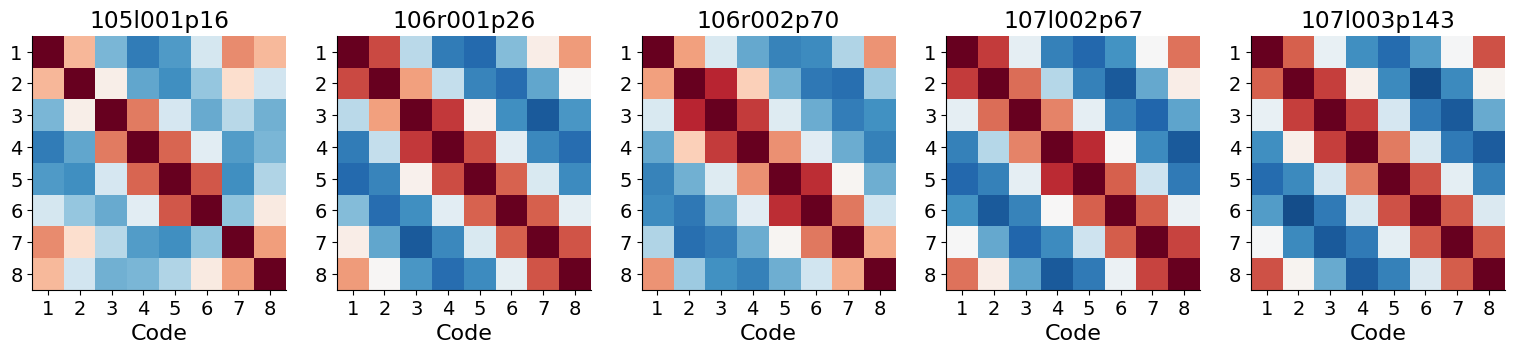

In [8]:
tuning = pd.read_csv(f'{OUT}/tuning.csv').merge(neurons[neurons.snr > 1][['session', 'neuron']])
fig, axs = plt.subplots(1, 5, figsize=(19, 3.8))
for ax, (session, d) in zip(axs, tuning.groupby('session')):
    m = d.pivot(index='neuron', columns='orientation', values='mean')
    z = m.sub(m.mean(axis=1), axis=0).div(m.std(axis=1), axis=0)
    corr = np.corrcoef(z.values.T)
    ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set(title=session, xticks=range(8), xticklabels=range(1, 9), yticks=range(8), yticklabels=range(1, 9), xlabel='Code')
    print(session, 'correlation of codes k and k+1 (8 -> 1):', np.round([corr[k, (k + 1) % 8] for k in range(8)], 2))
plt.show()

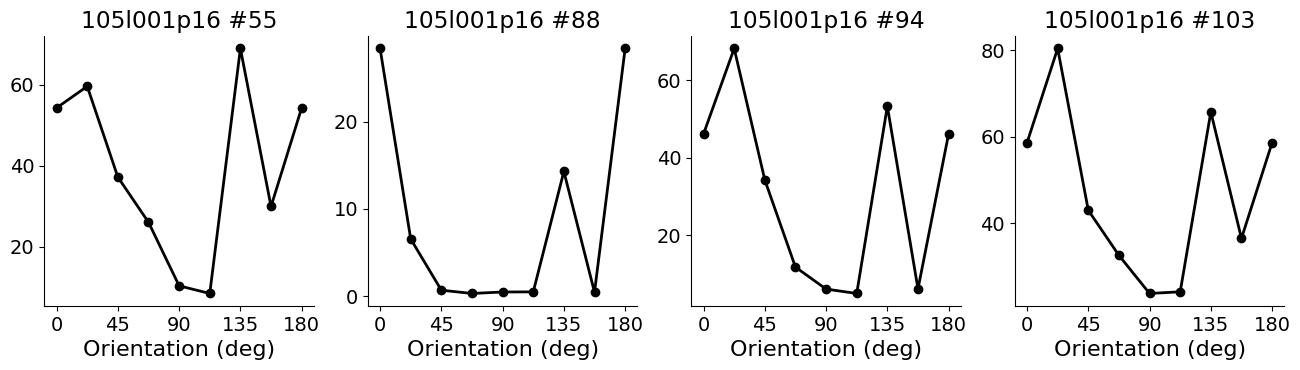

In [9]:
d = pd.read_csv(f'{OUT}/tuning.csv').query('session == "105l001p16" and neuron in [55, 88, 94, 103]')
fig, axs = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, (n, g) in zip(axs, d.groupby('neuron')):
    ax.plot(np.r_[g.orientation, 180], np.r_[g['mean'], g['mean'].iloc[0]], 'o-', color='k')
    ax.set(title=f'105l001p16 #{n}', xticks=[0, 45, 90, 135, 180], xlabel='Orientation (deg)')
plt.show()

In four sessions every pair of neighbouring codes is positively correlated (0.38 to 0.76), including 8 and 1,
so the codes are consecutive orientations on a circle. In 105l001p16 codes 6 and 7 are anti-correlated (-0.40),
codes 2 and 3 barely correlated (0.06), and many tuning curves jump at 135-157.5 deg (examples above), so the code
order there is unreliable. We use **107l003p143** (111 V1 neurons, many well tuned).

## 6. All tuning curves and the choice of neurons

Mean $\pm$ SD of every neuron in the session, sorted by signal-to-noise ratio
(SNR = variance of the tuning curve across orientations / mean trial-to-trial variance).

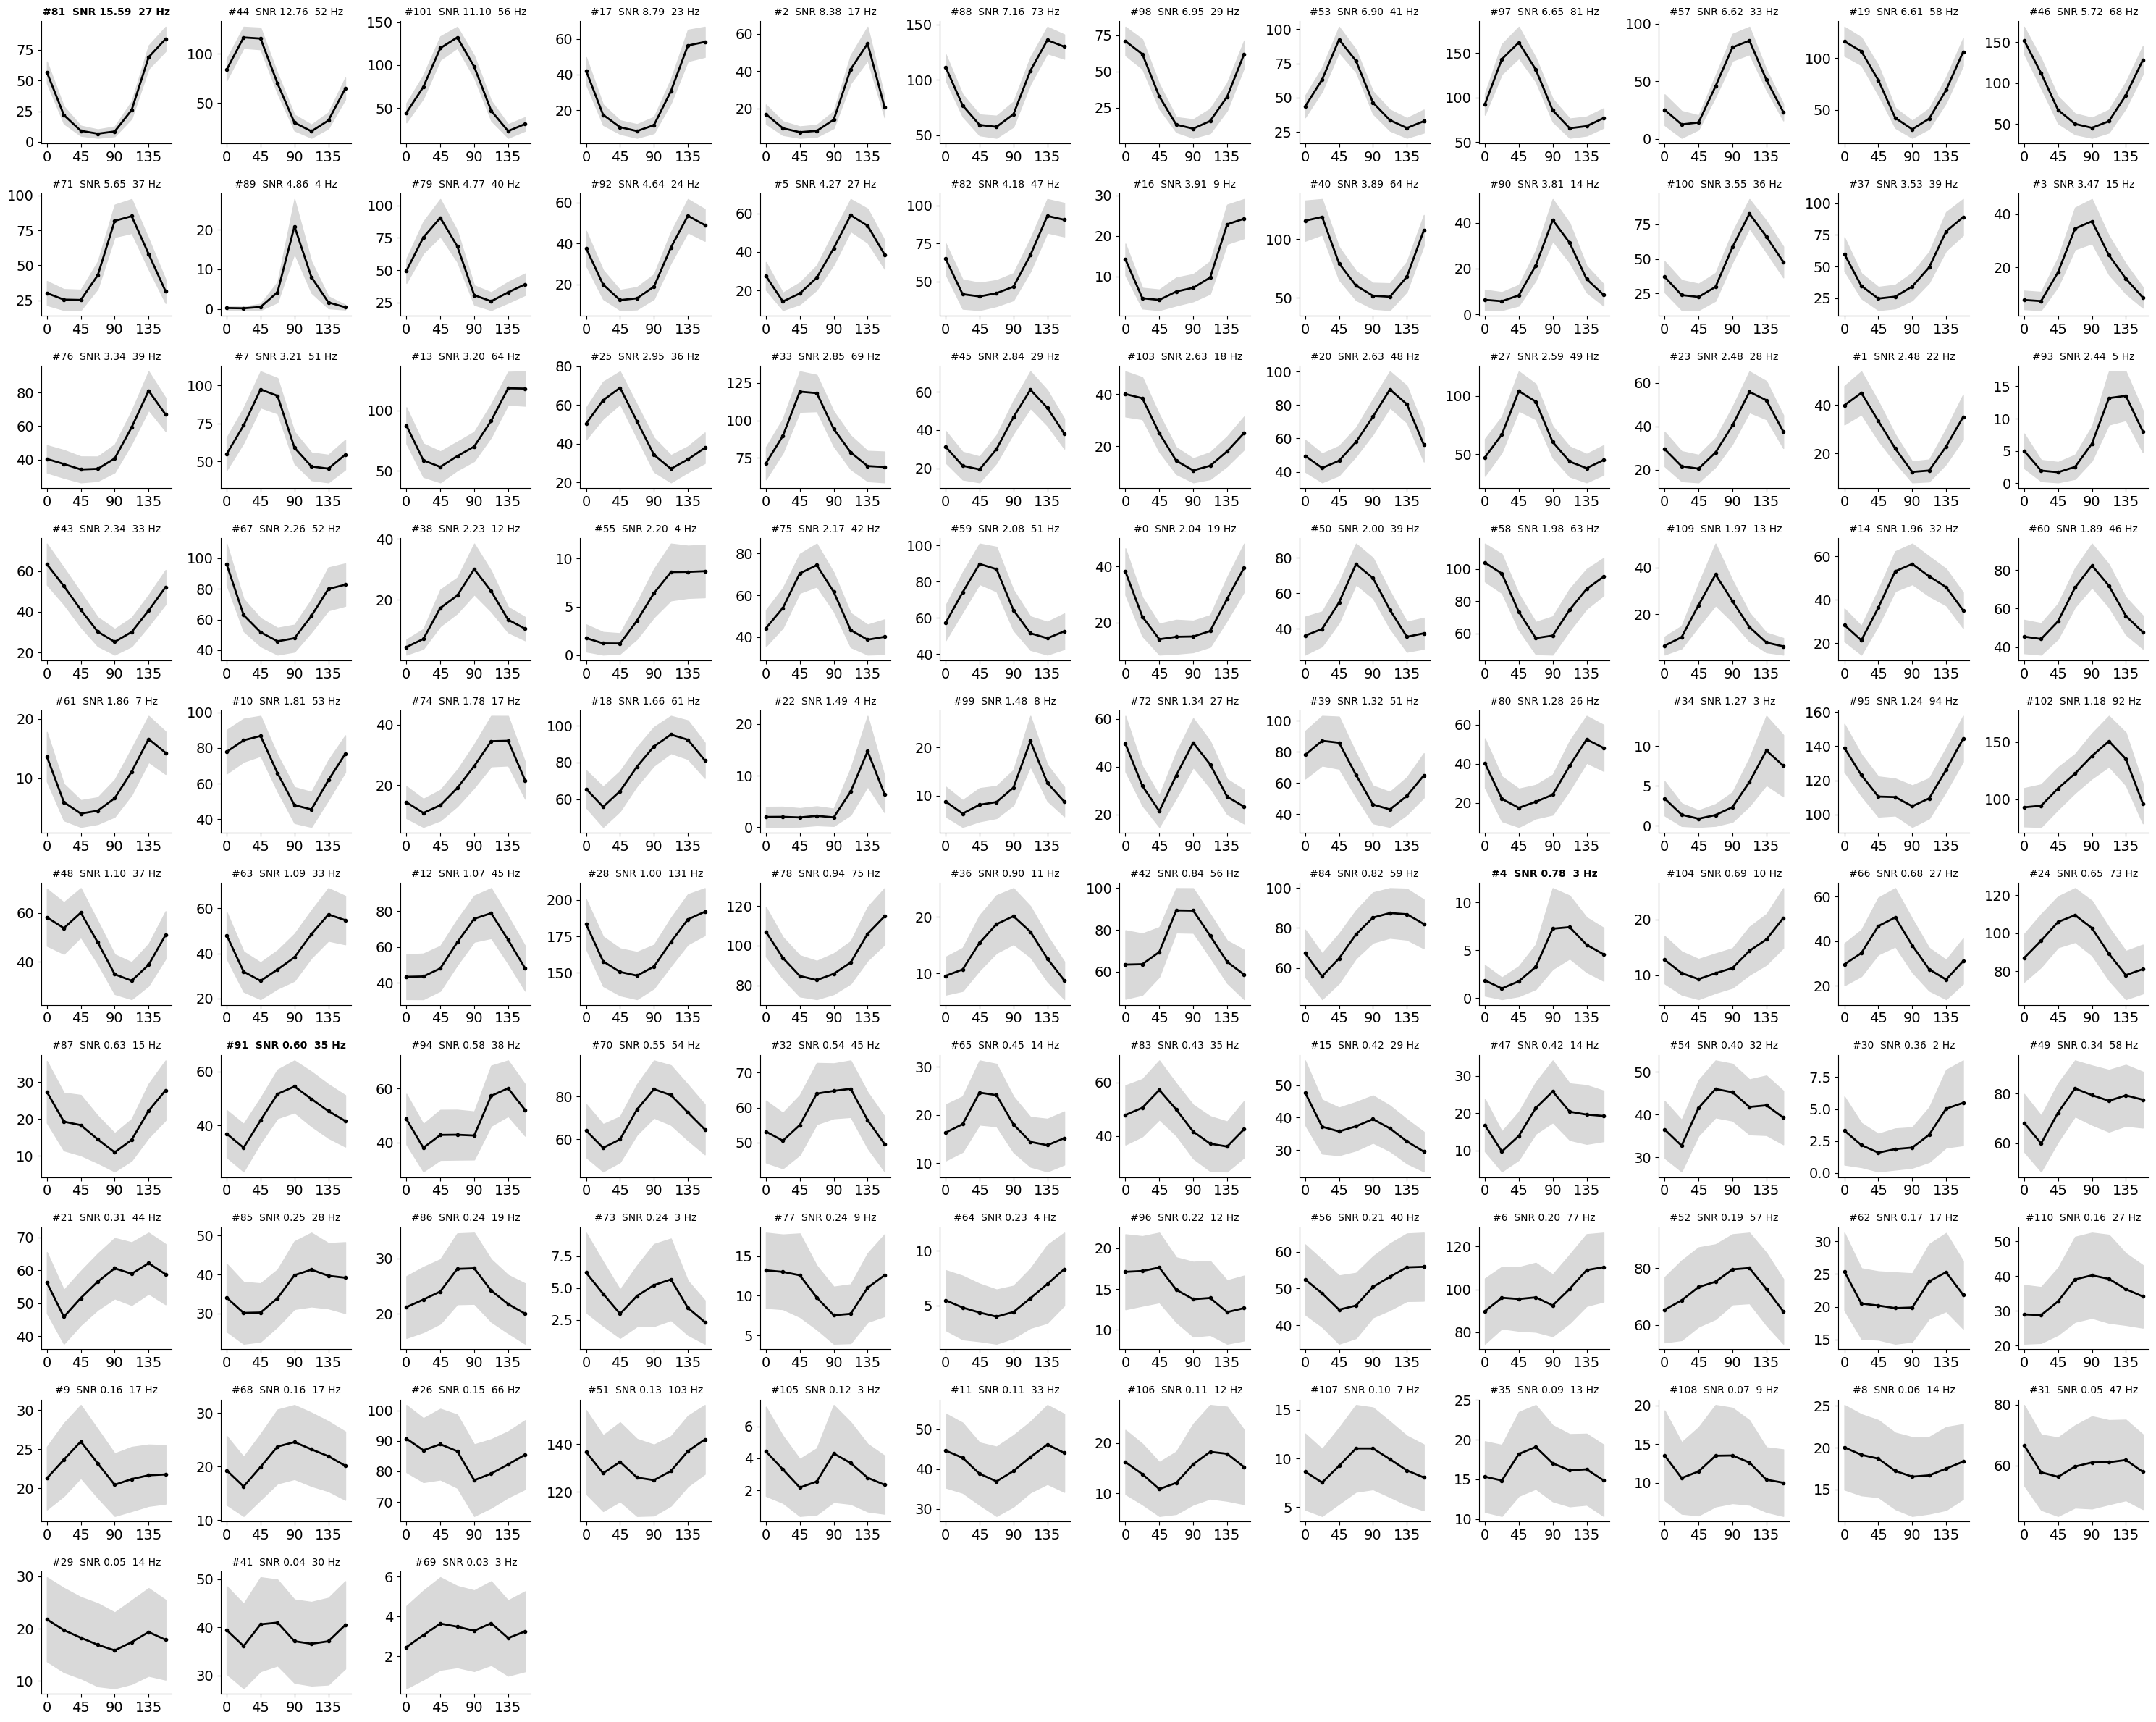

In [10]:
fig, axs = plt.subplots(10, 12, figsize=(30, 24))
for ax in axs.flat:
    ax.axis('off')
for ax, (n, row) in zip(axs.flat, nrn.sort_values('snr', ascending=False).iterrows()):
    g = tun[tun.neuron == n]
    ax.axis('on')
    ax.fill_between(g.orientation, g['mean'] - g.sd, g['mean'] + g.sd, color='0.85')
    ax.plot(g.orientation, g['mean'], 'o-', color='k', ms=3)
    ax.set_title(f'#{n}  SNR {row.snr:.2f}  {row.rate_hz:.0f} Hz', fontsize=10,
                 fontweight='bold' if n in [NEURON] + NOISY else 'normal')
    ax.set_xticks([0, 45, 90, 135])
fig.tight_layout()
plt.show()

In [11]:
print(nrn.sort_values('snr', ascending=False).head(8).round(2))
print()
print(nrn.loc[[NEURON] + NOISY].round(2))
print()
print('range of the mean response (spikes per trial):')
print(tun[tun.neuron.isin([NEURON] + NOISY)].groupby('neuron')['mean'].agg(['min', 'max']).round(1))

            session  rate_hz   pref   oti    snr  fano  drift
neuron                                                       
81      107l003p143    27.49  157.5  0.85  15.59  1.72   0.15
44      107l003p143    52.17   22.5  0.69  12.76  1.67   0.18
101     107l003p143    55.75   67.5  0.70  11.10  2.17   0.10
17      107l003p143    22.99  157.5  0.75   8.79  1.54  -0.07
2       107l003p143    16.82  135.0  0.76   8.38  1.43   0.18
88      107l003p143    72.98  135.0  0.40   7.16  1.39   0.22
98      107l003p143    29.27    0.0  0.74   6.95  2.52   0.06
53      107l003p143    40.66   45.0  0.54   6.90  1.48  -0.02

            session  rate_hz   pref   oti    snr  fano  drift
neuron                                                       
81      107l003p143    27.49  157.5  0.85  15.59  1.72   0.15
4       107l003p143     3.20  112.5  0.76   0.78  1.60   0.21
91      107l003p143    34.52   90.0  0.26   0.60  1.99   0.11

range of the mean response (spikes per trial):
         min   max
ne

**Neuron 81** has the highest SNR of the session, a large modulation (about 7 to 84 spikes per trial) and small drift.
It prefers 157.5 deg but still fires strongly at 0 deg: its tuning curve crosses the 0/180 deg boundary of the orientation
axis, which is exactly where part 4 of the homework matters. **Neurons 4 and 91** have a 20-26 times lower SNR
(0.78 and 0.60): #4 fires few spikes (about 1 to 7 per trial), #91 fires many but its tuning is shallow compared with
its trial-to-trial variability.